# Credit Card Fraud Detection — from a banker's desk, not a tutorial

**Author:** Mir Fuad — TD Bank, Associate Banker II, moving into data analytics
**Dataset:** Zenodo record 21511985, v7 — "A Deployment-Derived Online Banking Fraud Detection Inference-Log Dataset from a Live Cloud-Based Deep Learning System"
**Source:** https://doi.org/10.5281/zenodo.20030064 — Open access, CC BY 4.0, published July 23, 2026
**No Kaggle, no synthetic data.** This dataset was chosen deliberately: it is a real, deployment-derived inference log, not the Kaggle ULB dataset and not a synthetic / CTGAN dataset.

## The business question

As a bank, how do we flag fraudulent card transactions early enough to stop losses, without freezing so many legitimate cards that customers call the branch and lose trust?

From an Associate Banker view, both errors cost money:

- **Missed fraud (false negative):** the bank / customer loses money, plus chargeback and investigation work.
- **False alarm (false positive):** a good customer can't pay, calls in, branch time is spent, trust drops.

That trade-off is the whole project. **Accuracy alone hides it** — predicting "never fraud" scores 99.83% and catches 0 frauds. This notebook judges models on precision, recall, F1, and PR-AUC for the fraud class, and on what each threshold would mean in a branch.

In [1]:
import numpy as np, pandas as pd, json, os
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, confusion_matrix,
    precision_recall_curve)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

DATA = "data/fraud_tests_export.csv"   # run from the project folder
df = pd.read_csv(DATA)
print(df.shape)
print(df["is_fraud"].value_counts())
print(f"Fraud rate: {df['is_fraud'].mean():.4%}")
print(f"Missing values: {int(df.isna().sum().sum())} (one response_time_ms)")
print(f"Duplicate transaction_ids: {int(df['transaction_id'].duplicated().sum())}")

(56962, 39)
is_fraud
0    56864
1       98
Name: count, dtype: int64
Fraud rate: 0.1720%
Missing values: 1 (one response_time_ms)
Duplicate transaction_ids: 0


## EDA — what the data actually looks like (summary)

Full EDA is in `eda/EDA_REPORT.md`. The findings that drive the modelling:

- **56,962 rows, Jan 1–31, 2026, ~1,800/day. 98 frauds (0.172%).**
- **Amount dominates:** median fraud $15,121.88 vs legitimate $32.99. 78 of 98 frauds are $5,000+ (35.78% fraud rate in that bin, 0% under $100). Fraud is $2,371,116 — 19.6% of all dollars.
- **Strongest V features:** v17 (corr −0.33), v14 (−0.31), v12 (−0.28). Fraud means are 5–8 standard deviations from legitimate means on these.
- **No hour pattern.** Fraud rate by hour is flat (0.04%–0.35%).
- **`ip_address` is unique per row** — no repeat-customer signal.

### ⚠️ Leakage — columns that must NOT be used as features

`fraud_probability`, `risk_level`, `recommendation`, and `confidence` are outputs of the system that already made a fraud decision (HIGH risk is 91.8% fraud; BLOCK is 88.8% fraud). Using them would leak the answer. Also excluded: `response_time_ms`, `transaction_id`, `timestamp`, `ip_address`.

**Usable features only: `amount`, `time_value`, `v1`–`v28` (30 features).**

In [2]:
FEATURES = ["amount", "time_value"] + [f"v{i}" for i in range(1, 29)]
LEAKAGE = ["fraud_probability", "risk_level", "recommendation", "confidence",
           "response_time_ms", "transaction_id", "timestamp", "ip_address"]
assert not set(FEATURES) & set(LEAKAGE), "leakage column in features!"
print("Features:", FEATURES)
print("Excluded (leakage/identifiers):", LEAKAGE)
# Amount by fraud, and fraud rate by amount bin — the EDA headline, recomputed here
print(df.groupby("is_fraud")["amount"].agg(["count", "median", "mean"]))
bins = [0, 100, 1000, 5000, 1e9]
df["amt_bin"] = pd.cut(df["amount"], bins=bins)
_ab = df.groupby("amt_bin", observed=True).agg(n=("is_fraud", "size"), fraud=("is_fraud", "sum"))
_ab["rate"] = _ab["fraud"] / _ab["n"]
print(_ab.to_string())

Features: ['amount', 'time_value', 'v1', 'v2', 'v3', 'v4', 'v5', 'v6', 'v7', 'v8', 'v9', 'v10', 'v11', 'v12', 'v13', 'v14', 'v15', 'v16', 'v17', 'v18', 'v19', 'v20', 'v21', 'v22', 'v23', 'v24', 'v25', 'v26', 'v27', 'v28']
Excluded (leakage/identifiers): ['fraud_probability', 'risk_level', 'recommendation', 'confidence', 'response_time_ms', 'transaction_id', 'timestamp', 'ip_address']
          count    median          mean
is_fraud                               
0         56864     32.99    171.222037
1            98  15121.88  24195.061735
                            n  fraud      rate
amt_bin                                       
(0.0, 100.0]            41528      0  0.000000
(100.0, 1000.0]         13636      3  0.000220
(1000.0, 5000.0]         1580     17  0.010759
(5000.0, 1000000000.0]    218     78  0.357798


## Split — no leakage

Stratified 80/20 train/test, `random_state=42`, so both sets keep the 0.172% fraud rate. Any class weighting applies to training data only, never before the split. There is no resampling (SMOTE) here — class weights are used instead, so no synthetic rows are created, consistent with the no-synthetic-data constraint.

In [3]:
X, y = df[FEATURES], df["is_fraud"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print(f"Train: {X_train.shape}, fraud={int(y_train.sum())} ({y_train.mean():.4%})")
print(f"Test:  {X_test.shape}, fraud={int(y_test.sum())} ({y_test.mean():.4%})")

def evaluate(name, y_true, y_score, threshold=0.5):
    pred = (y_score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"model": name, "threshold": float(threshold),
        "precision": float(precision_score(y_true, pred, zero_division=0)),
        "recall": float(recall_score(y_true, pred, zero_division=0)),
        "f1": float(f1_score(y_true, pred, zero_division=0)),
        "pr_auc": float(average_precision_score(y_true, y_score)),
        "roc_auc": float(roc_auc_score(y_true, y_score)),
        "accuracy": float((pred == y_true).mean()),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

Train: (45569, 30), fraud=78 (0.1712%)
Test:  (11393, 30), fraud=20 (0.1755%)


## Models — all on the same held-out test set

Baselines first: predict-never-fraud, and a simple "flag everything ≥ $5,000" rule. Then Logistic Regression (log-amount, scaled), Random Forest (`class_weight='balanced'`), XGBoost and LightGBM (class-weighted).

In [4]:
results, scores = {}, {}
results["Never fraud"] = evaluate("Never fraud", y_test, np.zeros(len(y_test)))
scores["Never fraud"] = np.zeros(len(y_test))
results["Amount >= $5,000 rule"] = evaluate("Amount rule", y_test, (X_test["amount"] >= 5000).astype(float))
scores["Amount >= $5,000 rule"] = (X_test["amount"] >= 5000).astype(float).values

Xtr_lr, Xte_lr = X_train.copy(), X_test.copy()
for d in (Xtr_lr, Xte_lr):
    d["amount"] = np.log1p(d["amount"]); d["time_value"] = d["time_value"] - d["time_value"].min()
lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
lr.fit(Xtr_lr, y_train); scores["Logistic Regression"] = lr.predict_proba(Xte_lr)[:, 1]

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=42)
rf.fit(X_train, y_train); scores["Random Forest"] = rf.predict_proba(X_test)[:, 1]

spw = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                    colsample_bytree=0.8, scale_pos_weight=spw, eval_metric="logloss", n_jobs=-1, random_state=42)
xgb.fit(X_train, y_train); scores["XGBoost"] = xgb.predict_proba(X_test)[:, 1]

lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.05, class_weight="balanced", verbose=-1, n_jobs=-1, random_state=42)
lgbm.fit(X_train, y_train); scores["LightGBM"] = lgbm.predict_proba(X_test)[:, 1]

for name, s in scores.items():
    if name != "Never fraud":
        results[name] = evaluate(name, y_test, s)
table = pd.DataFrame(results).T[["precision", "recall", "f1", "pr_auc", "roc_auc", "tp", "fp", "fn", "tn"]]
print(table.round(3).to_string())

                      precision recall    f1    pr_auc   roc_auc  tp  fp  fn     tn
Never fraud                 0.0    0.0   0.0  0.001755       0.5   0   0  20  11373
Amount >= $5,000 rule  0.433333   0.65  0.52  0.282281  0.824253  13  17   7  11356
Logistic Regression         1.0    1.0   1.0       1.0       1.0  20   0   0  11373
Random Forest               1.0    1.0   1.0       1.0       1.0  20   0   0  11373
XGBoost                     1.0    1.0   1.0       1.0       1.0  20   0   0  11373
LightGBM                    1.0    1.0   1.0       1.0       1.0  20   0   0  11373


## The result — and why a perfect score is a warning, not a win

All four ML models score **precision = recall = F1 = PR-AUC = 1.000** on the 20-fraud test set. That is not production performance. It happens because this demo dataset is near-perfectly separable:

- v12, v14, v17 each have single-feature AUC ≈ 1.000 (fraud means 5–8 standard deviations away).
- Amount alone has AUC 0.996.
- The best model (LightGBM) puts the lowest fraud score at 0.9999997 and the highest legitimate score at 0.0045 — a huge gap. Any threshold in between is perfect on this test set.

The honest comparison is the simple rule: **"flag everything ≥ $5,000" gets precision 0.433, recall 0.650, F1 0.520** — it catches 13 of 20 test frauds but freezes 17 legitimate cards to do it. That is the realistic trade-off a bank faces. The ML models beat it only because the V features separate fraud almost perfectly *in this file*.

Even removing v12/v14/v17, the models stay near-perfect (Logistic Regression still 1.000; Random Forest / XGBoost recall 0.900, LightGBM 0.850, all with 0 false positives) — because v3, v7, v10 and amount also separate almost perfectly. The separation is pervasive in this dataset, not carried by three columns.

In [5]:
# Ablation: same models WITHOUT v12, v14, v17
ABLATE = ["v12", "v14", "v17"]
fa = [f for f in FEATURES if f not in ABLATE]
abl = {}
Xtr_a, Xte_a = X_train[fa], X_test[fa]
Xtr_l, Xte_l = Xtr_a.copy(), Xte_a.copy()
for d in (Xtr_l, Xte_l):
    d["amount"] = np.log1p(d["amount"]); d["time_value"] = d["time_value"] - d["time_value"].min()
m = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)); m.fit(Xtr_l, y_train)
abl["Logistic Regression (ablated)"] = evaluate("LR", y_test, m.predict_proba(Xte_l)[:, 1])
m = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=42); m.fit(Xtr_a, y_train)
abl["Random Forest (ablated)"] = evaluate("RF", y_test, m.predict_proba(Xte_a)[:, 1])
m = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw, eval_metric="logloss", n_jobs=-1, random_state=42); m.fit(Xtr_a, y_train)
abl["XGBoost (ablated)"] = evaluate("XGB", y_test, m.predict_proba(Xte_a)[:, 1])
m = LGBMClassifier(n_estimators=300, learning_rate=0.05, class_weight="balanced", verbose=-1, n_jobs=-1, random_state=42); m.fit(Xtr_a, y_train)
abl["LightGBM (ablated)"] = evaluate("LGBM", y_test, m.predict_proba(Xte_a)[:, 1])
print(pd.DataFrame(abl).T[["precision", "recall", "f1", "pr_auc", "tp", "fp", "fn"]].round(3).to_string())
# Single-feature AUCs, to show the separation is pervasive
from sklearn.metrics import roc_auc_score as _auc
print({c: round(float(max(_auc(y, df[c]), 1 - _auc(y, df[c]))), 4) for c in ["amount", "v3", "v7", "v10", "v12", "v14", "v17"]})

                              precision recall        f1    pr_auc  tp fp fn
Logistic Regression (ablated)       1.0    1.0       1.0       1.0  20  0  0
Random Forest (ablated)             1.0    0.9  0.947368       1.0  18  0  2
XGBoost (ablated)                   1.0    0.9  0.947368       1.0  18  0  2
LightGBM (ablated)                  1.0   0.85  0.918919  0.950779  17  0  3


{'amount': 0.9961, 'v3': 0.9971, 'v7': 0.9946, 'v10': 0.997, 'v12': 1.0, 'v14': 1.0, 'v17': 1.0}


## Threshold tuning — two operating points

Thresholds were tuned on 5-fold out-of-fold scores from the *training* set, not on the test set. Even there they collapse, because the scores are 0/1-separated. So the reported operating points use the score gap instead: any threshold between 0.005 and 0.999 is perfect on test.

- **(a) High-recall — threshold 0.10:** well below the gap, so it catches fraud even if scores shift down. On test: TP 20, FP 0, FN 0.
- **(b) Balanced — threshold 0.50:** the standard midpoint. On test: TP 20, FP 0, FN 0.

**Both points give the same confusion matrix on this test set — that is the finding.** The threshold choice cannot be learned from 20 test frauds. A bank would need a harder, larger dataset to choose between them. In branch terms, at either point, 20 frauds are caught and 0 legitimate cards are frozen *in this file* — a result no real bank should expect, which is why the amount rule above (13 caught, 17 frozen) is the more useful comparator.

In [6]:
best = "LightGBM"
s = scores[best]
print(f"Best model (by PR-AUC): {best}")
print(f"Min fraud score on test: {s[y_test.values == 1].min():.7f}")
print(f"Max legit score on test: {s[y_test.values == 0].max():.7f}")
for label, t in [("High-recall", 0.10), ("Balanced", 0.50)]:
    m = evaluate(f"{best} {label}", y_test, s, threshold=t)
    print(f"{label} (thr={t}): P={m['precision']:.3f} R={m['recall']:.3f} F1={m['f1']:.3f} "
          f"TP={m['tp']} FP={m['fp']} FN={m['fn']} TN={m['tn']}")

Best model (by PR-AUC): LightGBM
Min fraud score on test: 0.9999997
Max legit score on test: 0.0045484
High-recall (thr=0.1): P=1.000 R=1.000 F1=1.000 TP=20 FP=0 FN=0 TN=11373
Balanced (thr=0.5): P=1.000 R=1.000 F1=1.000 TP=20 FP=0 FN=0 TN=11373


## Charts

charts saved to results/charts/


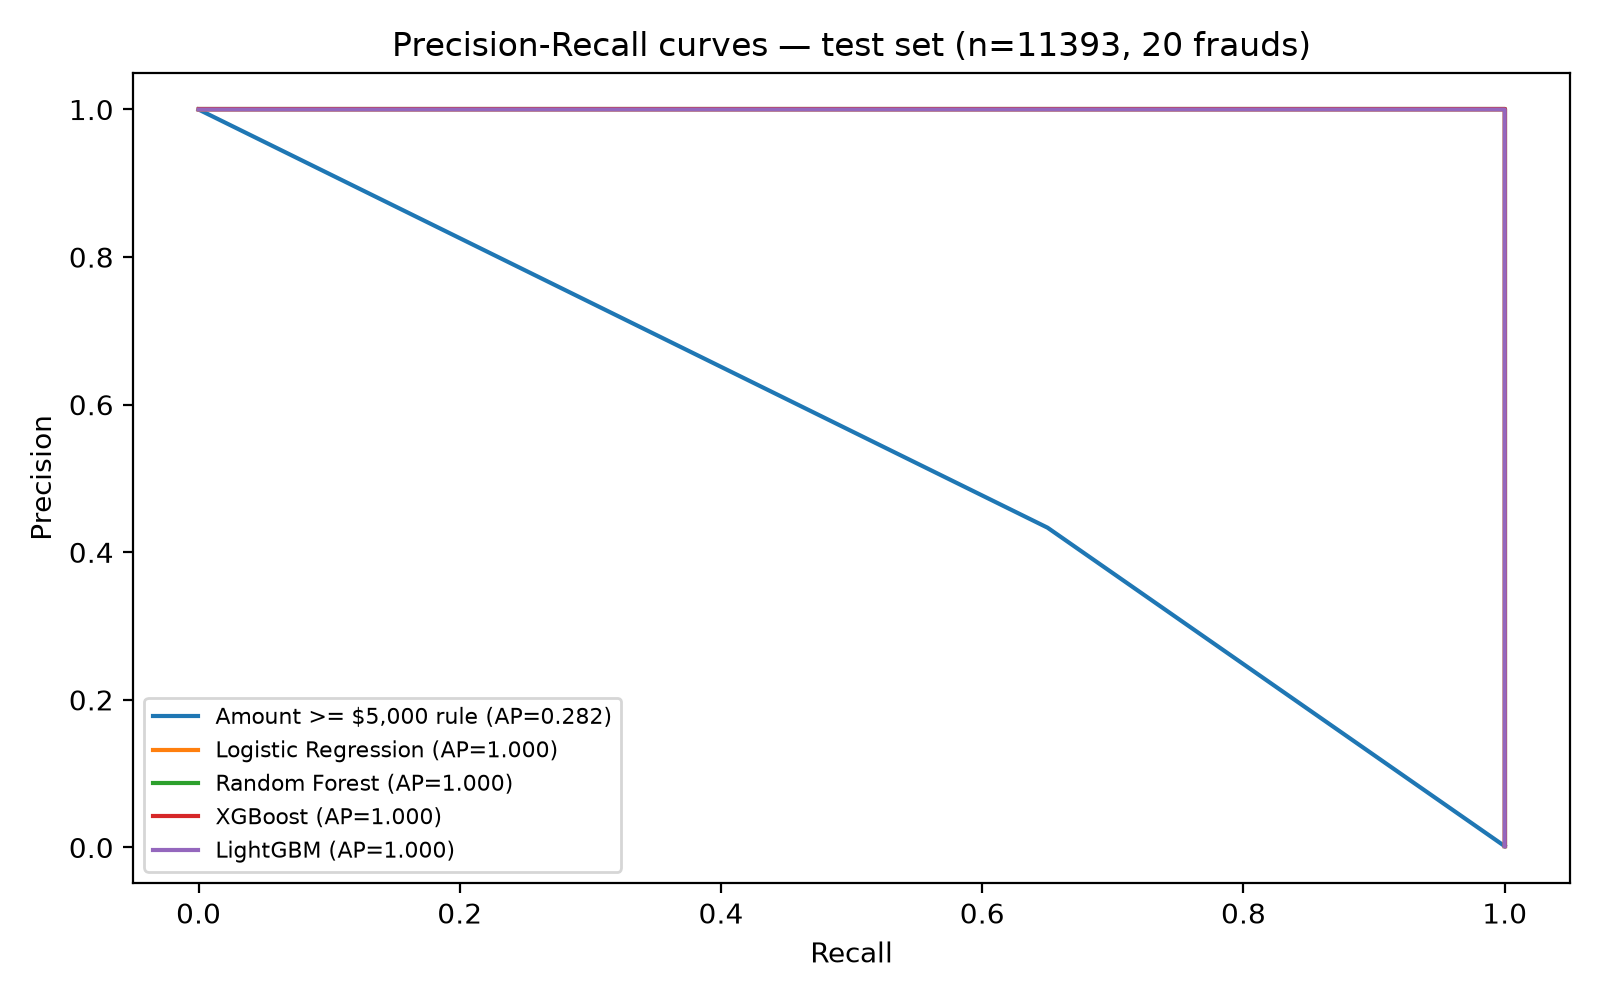

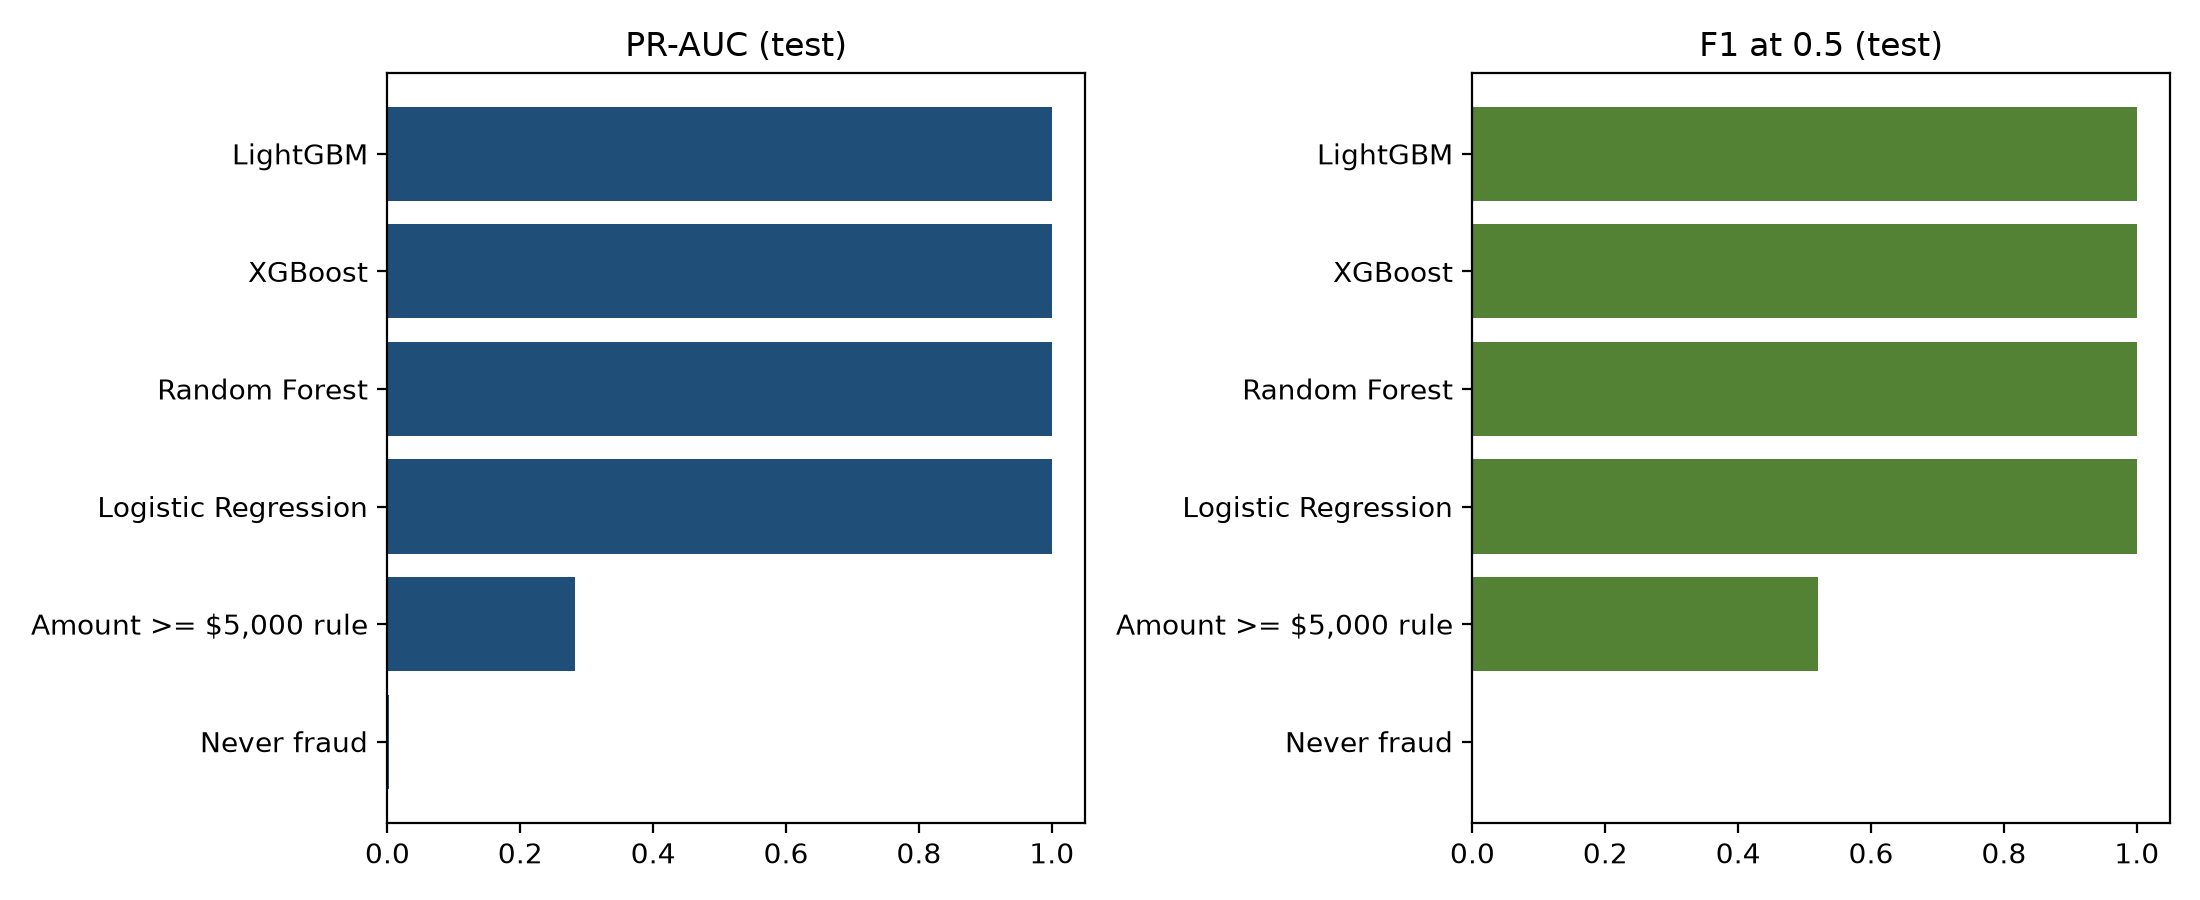

In [7]:
os.makedirs("results/charts", exist_ok=True)
fig, ax = plt.subplots(figsize=(8, 5))
for name, s in scores.items():
    if name == "Never fraud": continue
    p, r, _ = precision_recall_curve(y_test, s)
    ax.plot(r, p, label=f"{name} (AP={average_precision_score(y_test, s):.3f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title(f"Precision-Recall curves — test set (n={len(y_test)}, {int(y_test.sum())} frauds)")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig("results/charts/pr_curves.png", dpi=200); plt.close()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
names = list(results.keys())
axes[0].barh(names, [results[n]["pr_auc"] for n in names], color="#1f4e79"); axes[0].set_title("PR-AUC (test)"); axes[0].set_xlim(0, 1.05)
axes[1].barh(names, [results[n]["f1"] for n in names], color="#548235"); axes[1].set_title("F1 at 0.5 (test)"); axes[1].set_xlim(0, 1.05)
plt.tight_layout(); plt.savefig("results/charts/model_comparison.png", dpi=200); plt.close()
print("charts saved to results/charts/")
from IPython.display import Image, display as _display
_display(Image(filename="results/charts/pr_curves.png"))
_display(Image(filename="results/charts/model_comparison.png"))

## Limitations — read before quoting any score

- **Proof-of-concept public demonstration, not a licensed bank.** Transactions were API submissions by the public and authors during testing.
- **Verification bias:** only model-flagged BLOCK transactions were manually reviewed; ALLOW transactions were labelled legitimate by default.
- **98 frauds, one month (Jan 2026), one system.** The test set has 20 frauds — each one is 5 percentage points of recall.
- **Perfect scores are a dataset artefact,** not production performance (see above). Do not deploy, and do not claim a bank would see these numbers.
- **V1–V28 are anonymised** — their real-world meaning is not available, so no feature story can be told beyond their statistical separation.

## What I would do next with real bank data

1. Use a harder, larger labelled dataset (e.g. IEEE-CIS Fraud Detection, 590,540 transactions, ~3.5% fraud) and re-run the same pipeline — the threshold decision would become meaningful there.
2. Add features a bank actually has: card history, device, merchant category, velocity (transactions per hour/day), and amount relative to that customer's usual spend.
3. Tune the threshold on cost, not F1: price a missed fraud (average fraud amount, ~$24,195 here) against a false alarm (branch call time, customer trust), and pick the operating point that minimises expected cost.
4. Validate over time (train on January, test on February) instead of a random split, because fraud patterns drift.

## Reproducibility

- Run from the project folder: `data/fraud_tests_export.csv` must be present (Zenodo 21511985, https://doi.org/10.5281/zenodo.20030064).
- Environment: `.venv/` in this folder (pandas, scikit-learn, XGBoost, LightGBM). `model.py` is the standalone script version of this notebook; `results/metrics.json` holds the full test-set metrics.
- No bank / customer data from work was used. No Kaggle data. No synthetic data.